# 03 · Competição: Modelo A × Modelo B

| | Modelo A | Modelo B |
|---|---|---|
| Algoritmo | Regressão Logística | Random Forest |
| Por que | Linear, interpretável, base forte | Não linear, captura interações |
| Features | as eleitas no notebook 02 | as mesmas |
| Protocolo | CV estratificada (5 folds) no treino | o mesmo |

**Sem vazamento:** em cada fold, a votação de features é refeita só com o treino do fold, e os dois modelos recebem o mesmo conjunto. Depois, cada modelo é treinado no treino completo com as features eleitas do ciclo e serializado junto com o pré-processamento.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore", category=UserWarning)
# Localiza a raiz do repositório e torna o pacote src importável
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.utils import carregar_config, configurar_mlflow, ler_contexto, atualizar_contexto, tags_ciclo, caminho, salvar_json
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.preprocessamento import separar_xy
from src.modelagem import competir_cv, pipeline_modelo, calcular_metricas

ctx = ler_contexto(cfg)
eleitas = ctx["features_eleitas"]
proc = caminho(cfg["dados"]["processed_dir"])
treino = pd.read_csv(proc / "treino.csv"); validacao = pd.read_csv(proc / "validacao.csv")
X_tr, y_tr = separar_xy(treino, cfg); X_va, y_va = separar_xy(validacao, cfg)
print(ctx["cycle_id"], "| features:", eleitas)

c004-20261119-1929 | features: ['euribor3m', 'nr.employed', 'cons.price.idx', 'emp.var.rate', 'month', 'poutcome', 'cons.conf.idx', 'age']


## 1. Validação cruzada estratificada (mesmo protocolo para A e B)

In [3]:
cv = competir_cv(X_tr, y_tr, cfg)
metrica = cfg["avaliacao"]["metrica_principal"]
display(cv[["fold", "modelo", "algoritmo", "n_features", metrica, "roc_auc", "f1", "lift_top"]].round(4))
resumo_cv = cv.groupby(["modelo", "algoritmo"])[[metrica, "roc_auc", "f1", "lift_top"]].agg(["mean", "std"]).round(4)
display(resumo_cv)

,fold,modelo,algoritmo,n_features,average_precision,roc_auc,f1,lift_top
0,1,A,regressao_logistica,8,0.2902,0.7364,0.2984,2.6078
1,1,B,random_forest,8,0.3003,0.7516,0.3424,2.7675
2,2,A,regressao_logistica,8,0.2547,0.7199,0.2968,2.4956
3,2,B,random_forest,8,0.2631,0.7306,0.3167,2.6022
4,3,A,regressao_logistica,8,0.3188,0.7542,0.3135,2.7563
5,3,B,random_forest,8,0.3195,0.7621,0.3369,2.7350
6,4,A,regressao_logistica,8,0.3251,0.7559,0.3216,2.6925
7,4,B,random_forest,8,0.3255,0.7627,0.3335,2.9266
8,5,A,regressao_logistica,8,0.3022,0.7392,0.3053,2.6393
9,5,B,random_forest,8,0.2989,0.7498,0.3258,2.7457


average_precision         roc_auc              f1         lift_top        
                                        mean     std    mean     std    mean     std     mean     std
modelo algoritmo                                                                                     
A      regressao_logistica            0.2982  0.0279  0.7411  0.0147  0.3071  0.0105   2.6383  0.0977
B      random_forest                  0.3015  0.0244  0.7514  0.0130  0.3311  0.0100   2.7554  0.1156

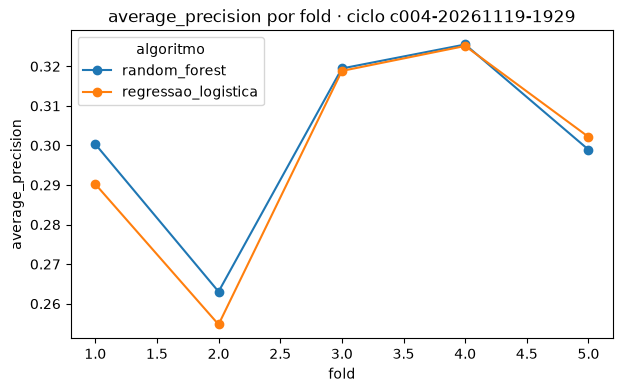

In [4]:
ax = cv.pivot(index="fold", columns="algoritmo", values=metrica).plot(marker="o", figsize=(7, 4))
ax.set_ylabel(metrica); ax.set_title(f"{metrica} por fold · ciclo {ctx['cycle_id']}"); plt.show()

## 2. Treino final dos dois candidatos + registro no MLflow

In [5]:
import joblib
from mlflow.models import infer_signature
mlflow = configurar_mlflow(cfg)
seed = cfg["projeto"]["seed"]; pct = cfg["negocio"]["percentual_contato"]
cand_dir = caminho(cfg["dados"]["state_dir"]) / "candidatos"; cand_dir.mkdir(parents=True, exist_ok=True)
candidatos = {}

for chave in ("A", "B"):
    spec = cfg["modelos"][chave]
    pipe = pipeline_modelo(eleitas, spec, seed).fit(X_tr, y_tr)
    m_val = calcular_metricas(y_va, pipe.predict_proba(X_va)[:, 1], pct)
    cv_m = cv[cv["modelo"] == chave]
    with mlflow.start_run(run_name=f"{ctx['cycle_id']}_03_modelo_{chave}_{spec['nome']}",
                          tags={**tags_ciclo(ctx, "03_treino"), "modelo": chave, "algoritmo": spec["nome"]}) as run:
        mlflow.log_params({"modelo": chave, "algoritmo": spec["nome"], "seed": seed, "features": ",".join(eleitas),
                           "n_features": len(eleitas), "cv": f"StratifiedKFold({cfg['avaliacao']['cv_folds']})",
                           **{f"hp_{k}": v for k, v in spec["params"].items()}})
        mlflow.log_metrics({f"cv_{metrica}_media": cv_m[metrica].mean(), f"cv_{metrica}_desvio": cv_m[metrica].std(),
                            "cv_roc_auc_media": cv_m["roc_auc"].mean(), "cv_f1_media": cv_m["f1"].mean(),
                            **{f"val_{k}": v for k, v in m_val.items()}})
        mlflow.log_table(cv_m, f"cv_folds_{chave}.json")
        mlflow.sklearn.log_model(pipe, name="modelo", serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
                                 code_paths=[str(caminho("src"))], signature=infer_signature(X_tr.head(50), pipe.predict_proba(X_tr.head(50))))
        candidatos[chave] = {"run_id": run.info.run_id, "algoritmo": spec["nome"], "val": m_val,
                             f"cv_{metrica}_media": float(cv_m[metrica].mean()), f"cv_{metrica}_desvio": float(cv_m[metrica].std())}
    joblib.dump(pipe, cand_dir / f"{chave}.joblib")
    print(f"Modelo {chave} ({spec['nome']}): CV {metrica} = {cv_m[metrica].mean():.4f} ± {cv_m[metrica].std():.4f} | run {run.info.run_id}")

cv.to_csv(caminho(cfg["dados"]["state_dir"]) / "cv_ciclo.csv", index=False)
atualizar_contexto(cfg, candidatos=candidatos)

2026/11/19 19:30:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Modelo A (regressao_logistica): CV average_precision = 0.2982 ± 0.0279 | run eb269ddb5a764b939d0eb1550cf14f0e


2026/11/19 19:30:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Modelo B (random_forest): CV average_precision = 0.3015 ± 0.0244 | run eb2ba708ac5c4e518e6052f8de919b7d


{'cycle_id': 'c004-20261119-1929',
 'data_version': 'v004-ce2b8d77',
 'execucao': {'gatilho': 'schedule',
  'github_run_id': '44598683474',
  'github_run_url': 'https://github.com/weillerjulia/n3-mlops-bank-marketing/actions/runs/44598683474',
  'commit': 'e96847b',
  'iniciado_em': '2026-11-19T19:29:23+00:00'},
 'lote': {'novo': True,
  'lote': 3,
  'arquivo': 'data/raw/lote_003.csv',
  'periodos': ['2009-08', '2009-09', '2009-10'],
  'linhas': 1484,
  'sha256': '3f271afeb294',
  'ingerido_em': '2026-11-19T19:29:23+00:00'},
 'drift_alerta': True,
 'features_com_drift': ['emp.var.rate',
  'cons.price.idx',
  'nr.employed',
  'month',
  'euribor3m',
  'cons.conf.idx',
  'job',
  'poutcome',
  'faixa_etaria',
  'pdays',
  'contact',
  'default',
  'age',
  'campaign'],
 'psi_max': 11.7757,
 'run_etl': 'c98d641b168042578b2e6fc1d7c0d018',
 'features_eleitas': ['euribor3m',
  'nr.employed',
  'cons.price.idx',
  'emp.var.rate',
  'month',
  'poutcome',
  'cons.conf.idx',
  'age'],
 'run_vot